Dataset shape: (150, 4)
Number of flowers: 150
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


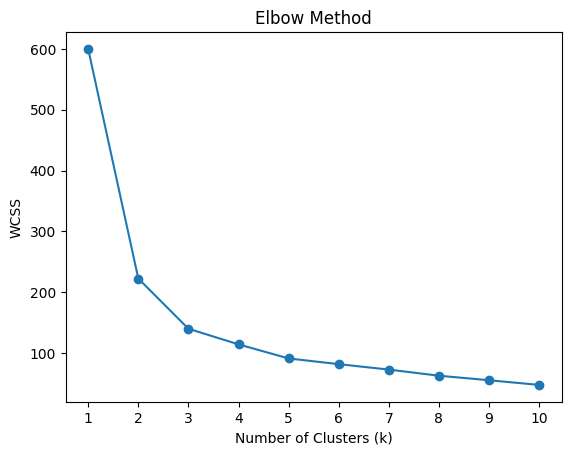

Cluster sizes:
Cluster 0 : 53 flowers
Cluster 1 : 50 flowers
Cluster 2 : 47 flowers


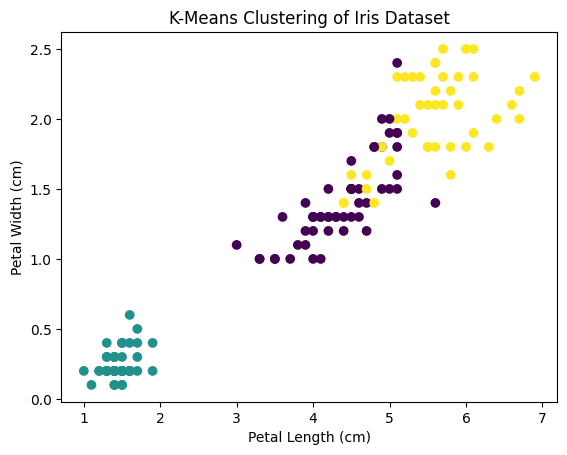

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Load built-in Iris dataset
iris = load_iris()
X = iris.data

print("Dataset shape:", X.shape)
print("Number of flowers:", len(X))
print("Features:", iris.feature_names)

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Elbow method
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

# Plot elbow graph
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.show()

# Final K-Means model with 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

print("Cluster sizes:")
for i in range(3):
    print("Cluster", i, ":", sum(clusters == i), "flowers")

# Visualize clusters using petal measurements
plt.scatter(X[:, 2], X[:, 3], c=clusters)
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("K-Means Clustering of Iris Dataset")
plt.show()